# Exploration du corpus

Ce notebook décrit les 4 982 problèmes et relie chaque constat à un choix du modèle.

* La partie 1 lit seulement `data/splits/split_summary.json` (versionné) et fonctionne sans les données.
* La partie 2 lit `data/processed/problems.jsonl`, produit par `python -m algo_tags preprocess --raw <dossier des JSON>`.

Le notebook n'entraîne aucun modèle.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/splits/split_summary.json").exists())
summary = json.loads((ROOT / "data/splits/split_summary.json").read_text(encoding="utf-8"))
TAGS = summary["target_order"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Le découpage de référence

60 / 20 / 20 par stratification multilabel, avec une colonne « aucun tag » pour que les problèmes sans cible soient aussi répartis équitablement.

In [2]:
counts = pd.DataFrame({name: {"problèmes": part["records"], "sans tag": part["without_target"]}
                       for name, part in summary["splits"].items()}).T
counts["part sans tag (%)"] = (100 * counts["sans tag"] / counts["problèmes"]).round(1)
counts

,problèmes,sans tag,part sans tag (%)
train,2981,1382,46.4
validation,997,461,46.2
test,1004,461,45.9


,train,validation,test
math,844,282,282
graphs,325,109,108
strings,253,85,84
number theory,210,70,70
trees,194,65,65
geometry,100,33,33
games,63,21,21
probabilities,55,19,18


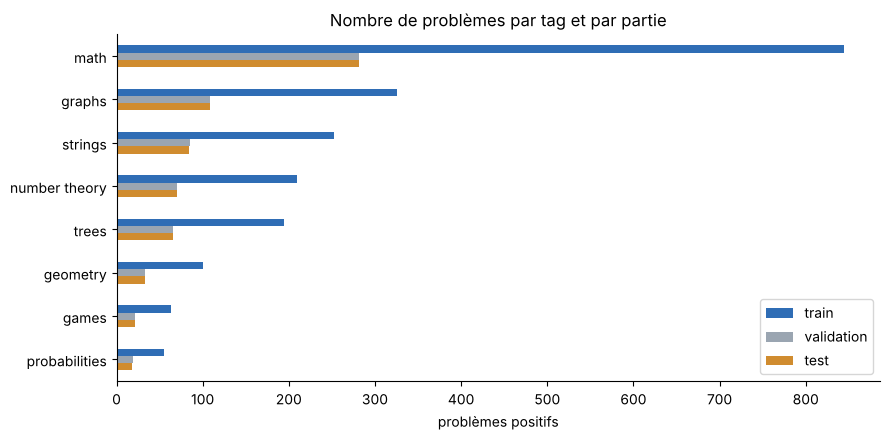

In [3]:
supports = pd.DataFrame({name: part["positive_counts"] for name, part in summary["splits"].items()}).reindex(TAGS)
ax = supports.plot.barh(color=["#2f6db5", "#9aa5b1", "#d08c2f"])
ax.invert_yaxis()
ax.set_xlabel("problèmes positifs")
ax.set_title("Nombre de problèmes par tag et par partie")
plt.tight_layout()
supports

Les proportions sont les mêmes dans les trois parties : les scores mesurés sur validation et test sont comparables.
`games` et `probabilities` n'ont qu'une vingtaine d'exemples en validation et en test, d'où un F1 très variable quand on le mesure sur une seule partie. C'est une des raisons de comparer les modèles en validation croisée répétée (voir le README, « Protocole et métriques »).

## 2. Le contenu des problèmes

Cette partie demande le fichier préparé. Si `data/processed/problems.jsonl` n'existe pas, lancer d'abord `preprocess`.

In [4]:
path = ROOT / "data/processed/problems.jsonl"
problems = [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines()]
y = pd.DataFrame([p["targets"] for p in problems], columns=TAGS)
n_tags = y.sum(axis=1)
print(f"{len(problems)} problèmes")
pd.DataFrame({"fréquence (%)": (100 * y.mean()).round(1)}).T

4982 problèmes


,math,graphs,strings,number theory,trees,geometry,games,probabilities
fréquence (%),28.3,10.9,8.5,7.0,6.5,3.3,2.1,1.8


### Combien de tags par problème ?

In [5]:
per_count = pd.DataFrame({"problèmes": n_tags.value_counts().sort_index(),
                          "part (%)": (100 * n_tags.value_counts(normalize=True).sort_index()).round(1)})
per_count.rename_axis("nombre de tags")

,problèmes,part (%)
nombre de tags,,
0,2304,46.2
1,2019,40.5
2,596,12.0
3,55,1.1
4,7,0.1
5,1,0.0


46 % des problèmes n'ont **aucun** des huit tags (ils sont tagués `greedy`, `dp`, etc.). Ils sont gardés, car le modèle rencontrera ce cas en production.
Conséquence pour le modèle : prédire « rien » doit être une réponse possible et mesurée. D'où la métrique **F1 macro9** : la moyenne des F1 des 8 tags et du F1 de la réponse « aucun tag ». S'y ajoute le suivi des fausses alertes, c'est-à-dire des problèmes sans tag qui en reçoivent un.

Seuls 13 % des problèmes ont plusieurs tags : on traite chaque tag par un classifieur binaire indépendant (*binary relevance*), sans modéliser les combinaisons.

### Quels tags vont ensemble ?

Cellule (ligne *i*, colonne *j*) : part des problèmes du tag *i* qui portent aussi le tag *j*.

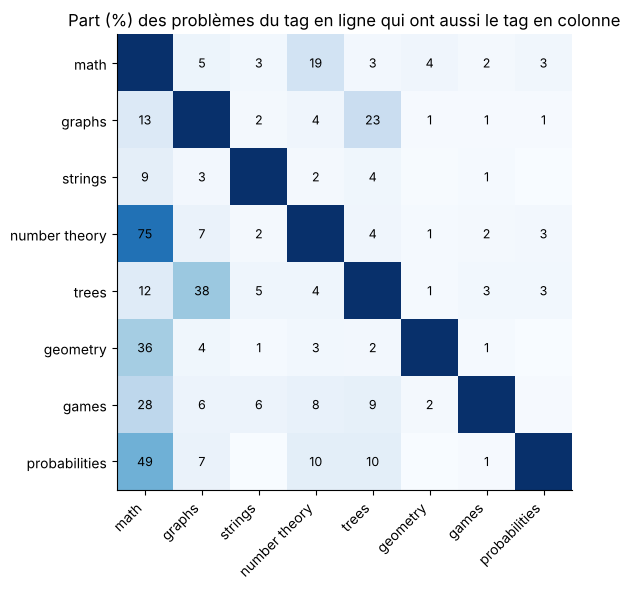

In [6]:
co = y.T @ y
share = 100 * co / np.diag(co)[:, None]
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(share, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(TAGS)), TAGS, rotation=45, ha="right")
ax.set_yticks(range(len(TAGS)), TAGS)
for i in range(len(TAGS)):
    for j in range(len(TAGS)):
        if i != j and share.iloc[i, j] >= 1:
            ax.text(j, i, f"{share.iloc[i, j]:.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Part (%) des problèmes du tag en ligne qui ont aussi le tag en colonne")
plt.tight_layout()

Ces recouvrements expliquent une bonne partie des erreurs du modèle :

* 75 % des problèmes `number theory` sont aussi `math`, et la moitié des `probabilities` aussi ;
* 38 % des problèmes `trees` sont aussi `graphs` (un arbre est un graphe) ;
* `math` recoupe presque tous les tags.

Les frontières entre ces tags sont floues dans les annotations elles-mêmes. On les retrouve dans la matrice de confusion entre tags (`results/test_final/tag_confusion.png`).

### Les tags dépendent-ils de la difficulté ?

difficulté inconnue : 54 problèmes


,≤ 1200,1300 à 1600,1700 à 2000,2100 à 2400,> 2400
math,33.0,27.0,25.0,26.0,32.0
graphs,2.0,8.0,15.0,20.0,18.0
strings,10.0,9.0,8.0,8.0,4.0
number theory,5.0,7.0,7.0,9.0,9.0
trees,0.0,4.0,9.0,13.0,11.0
geometry,2.0,2.0,4.0,5.0,7.0
games,2.0,1.0,2.0,2.0,4.0
probabilities,0.0,0.0,2.0,4.0,6.0
aucun tag,53.0,54.0,44.0,36.0,35.0


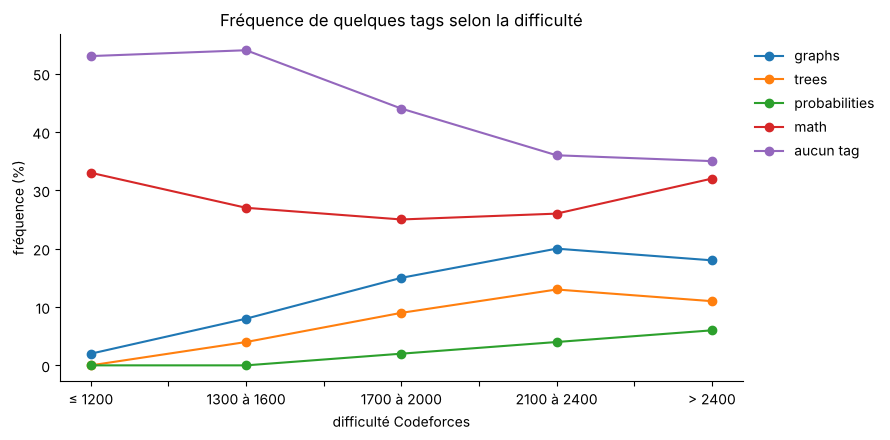

In [7]:
difficulty = pd.Series([p["difficulty"] for p in problems], dtype=float)
bands = pd.cut(difficulty, [0, 1200, 1600, 2000, 2400, 4000],
               labels=["≤ 1200", "1300 à 1600", "1700 à 2000", "2100 à 2400", "> 2400"])
by_band = (100 * y.assign(**{"aucun tag": n_tags == 0}).groupby(bands, observed=True).mean()).round(0)
print(f"difficulté inconnue : {difficulty.isna().sum()} problèmes")
ax = by_band[["graphs", "trees", "probabilities", "math", "aucun tag"]].plot(marker="o")
ax.set_ylabel("fréquence (%)")
ax.set_xlabel("difficulté Codeforces")
ax.set_title("Fréquence de quelques tags selon la difficulté")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
by_band.T

`graphs` passe de 2 % des problèmes faciles à environ 20 % des difficiles, et la part sans tag baisse de 53 % à 35 %. La difficulté est donc un indice utile : elle entre dans le modèle comme un petit bloc de features (rating et paliers).
`math`, lui, reste entre 25 et 33 % quel que soit le niveau : ce n'est pas un tag « problèmes faciles ».

### Ce que disent les exemples d'entrée et de sortie

In [8]:
real_answer = pd.Series([bool(re.search(r"\d\.\d", p["sample_out"])) for p in problems])
group = y["probabilities"].map({0: "autres problèmes", 1: "probabilities"})
(100 * real_answer.groupby(group).mean()).round(1).to_frame("sortie attendue décimale (%)")

,sortie attendue décimale (%)
probabilities,
autres problèmes,2.6
probabilities,42.4


42 % des problèmes `probabilities` attendent une réponse décimale dans leurs exemples, contre 3 % des autres. Le même raisonnement donne d'autres indices : des lignes « u v » dans l'entrée pour `graphs` et `trees`, des noms de joueurs (« Alice », « First ») dans la sortie pour `games`. Ces 11 indices forment le bloc `samples`.

### Taille de l'énoncé et du code

In [9]:
sizes = pd.DataFrame({"mots de l'énoncé": [len(p["statement"].split()) for p in problems],
                      "lignes de la solution": [len(p["code"].splitlines()) for p in problems]})
sizes.describe(percentiles=[0.5, 0.9]).round(0).T

,count,mean,std,min,50%,90%,max
mots de l'énoncé,4982.0,337.0,124.0,53.0,323.0,497.0,934.0
lignes de la solution,4982.0,51.0,79.0,1.0,32.0,105.0,2042.0


Chaque problème a une solution Python acceptée (32 lignes en médiane). Le code dit souvent *comment* le problème est résolu (`gcd`, `visited`, `queue`, `parent`), ce que l'énoncé ne dit qu'indirectement. C'est la source d'information qui apporte le plus : retirer le code et sa structure du modèle final lui fait perdre 1,7 point de F1 macro9 en validation croisée (voir `results/cv/`).

## Ce qu'on retient pour la modélisation

| Constat | Choix |
|---|---|
| 46 % des problèmes sans tag | métrique F1 macro9, seuil de décision choisi pour elle, suivi des fausses alertes |
| tags rares (`games`, `probabilities`) | moyenne macro (chaque tag compte autant), `class_weight="balanced"` dans le SVM, validation croisée répétée |
| recouvrements `trees`/`graphs`, `number theory`/`math` | un classifieur par tag, erreurs analysées avec la matrice de confusion entre tags |
| la difficulté change la répartition des tags | bloc `difficulty` |
| les exemples trahissent certains tags | bloc `samples` |
| le code montre la méthode de résolution | blocs `code` et `ast` |